# PATCHCORE — TRAINING SET CONTAMINATION DATASET GENERATION(MVTec AD Bottle)

**MOUNT GOOGLE DRIVE**

In [1]:
from google.colab import files
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


**Step 1: IMPORTS**

In [2]:
import os
import random
import shutil
import csv
from pathlib import Path

from PIL import Image, ImageEnhance

**Dataset Extracting**

In [3]:
from pathlib import Path

PROJECT_ROOT = Path(
    "/content/drive/MyDrive/Colab Notebooks/M.Tech AIML/"
    "Semester 1/Machine Learning/IAD_PROJECT"
)

ARCHIVE_PATH = PROJECT_ROOT / "Dataset" / "bottle.tar.xz"

print("Archive path:")
print(ARCHIVE_PATH)

print("\nArchive exists:", ARCHIVE_PATH.exists())

if ARCHIVE_PATH.exists():
    print("Archive size:", round(ARCHIVE_PATH.stat().st_size / (1024**2), 2), "MB")

Archive path:
/content/drive/MyDrive/Colab Notebooks/M.Tech AIML/Semester 1/Machine Learning/IAD_PROJECT/Dataset/bottle.tar.xz

Archive exists: True
Archive size: 148.66 MB


In [4]:
import tarfile
from pathlib import Path

archive = Path(
    "/content/drive/MyDrive/Colab Notebooks/M.Tech AIML/"
    "Semester 1/Machine Learning/IAD_PROJECT/Dataset/bottle.tar.xz"
)

extract_path = Path("/content")

if not archive.exists():
    raise FileNotFoundError("Bottle dataset archive not found.")

with tarfile.open(archive, "r:xz") as tar:
    tar.extractall(extract_path)

print("Dataset extracted successfully.")

/tmp/ipykernel_390/3857484133.py:15: DeprecationWarning: Python 3.14 will, by default, filter extracted tar archives and reject files or modify their metadata. Use the filter argument to control this behavior.
  tar.extractall(extract_path)


Dataset extracted successfully.


In [5]:
import os

print(os.listdir("/content"))

['.config', 'drive', 'bottle', 'sample_data']


**Step 2: VERIFY CONTAMINATION EXPERIMENT SETUP & CHECK PATHS**

In [6]:
PROJECT_ROOT = Path(
    "/content/drive/MyDrive/Colab Notebooks/M.Tech AIML/"
    "Semester 1/Machine Learning/IAD_PROJECT"
)

DATASET_ROOT = Path("/content/bottle")

TRAIN_GOOD = DATASET_ROOT / "train" / "good"
TEST_ROOT = DATASET_ROOT / "test"

print("Project:", PROJECT_ROOT)
print("Training:", TRAIN_GOOD)
print("Test:", TEST_ROOT)

print("\nTraining folder exists:", TRAIN_GOOD.exists())
print("Test folder exists:", TEST_ROOT.exists())


Project: /content/drive/MyDrive/Colab Notebooks/M.Tech AIML/Semester 1/Machine Learning/IAD_PROJECT
Training: /content/bottle/train/good
Test: /content/bottle/test

Training folder exists: True
Test folder exists: True


**Step 4: COUNT TRAINING & TEST IMAGES**

In [7]:
# Count training images
train_images = list(TRAIN_GOOD.glob("*"))
train_images = [x for x in train_images if x.is_file()]

# Count test images
test_images = list(TEST_ROOT.rglob("*"))
test_images = [x for x in test_images if x.is_file()]

print("Training images:", len(train_images))
print("Test images:", len(test_images))

Training images: 209
Test images: 83


**Step: Creating contamination experiment folders**

In [8]:
OUTPUT_ROOT = PROJECT_ROOT / "Contaminated_Data"

OUTPUT_ROOT.mkdir(exist_ok=True)

for level in ["5_percent", "10_percent", "20_percent"]:
    (OUTPUT_ROOT / level / "train" / "good").mkdir(
        parents=True,
        exist_ok=True
    )

print("Contamination experiment folders created.")
print(OUTPUT_ROOT)

Contamination experiment folders created.
/content/drive/MyDrive/Colab Notebooks/M.Tech AIML/Semester 1/Machine Learning/IAD_PROJECT/Contaminated_Data


**Step: Generate contaminated training images**

In [9]:
import cv2, numpy as np, random, shutil

random.seed(2026)
np.random.seed(2026)

train = sorted(TRAIN_GOOD.glob("*.png"))
root = PROJECT_ROOT / "Contaminated_Data"
pool = root / "FINAL_DEFECTS" / "pool"
pool.mkdir(parents=True, exist_ok=True)

for f in pool.glob("*.png"):
    f.unlink()

for i in range(42):

    img = cv2.imread(str(train[i]))
    h, w = img.shape[:2]

    # Choose a potential size for the defect
    original_size_choice = random.randint(110, 150)
    half = original_size_choice // 2

    # choose bottle location
    gray = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)
    ys, xs = np.where(gray < 200)

    j = random.randrange(len(xs))
    cx, cy = xs[j], ys[j]

    x1,x2 = cx-half,cx+half
    y1,y2 = cy-half,cy+half

    # Skip if the defect goes out of image bounds
    if x1 < 0 or y1 < 0 or x2 > w or y2 > h:
        continue

    # Determine the actual dimensions of the patch being modified
    patch_height = y2 - y1
    patch_width = x2 - x1

    # Create mask with the correct dimensions matching the image slice
    mask = np.zeros((patch_height, patch_width), np.uint8)

    # irregular dark contamination
    cv2.ellipse(
        mask,
        (patch_width//2, patch_height//2), # Center relative to the actual patch size
        (random.randint(35,55), random.randint(25,50)),
        random.randint(0,180), 0, 360, 255, -1
    )

    mask = cv2.GaussianBlur(mask, (0,0), 5)

    # dark brown/grey foreign material
    defect = np.zeros((patch_height, patch_width,3), np.uint8) # Create defect with correct dimensions
    defect[:] = (
        random.randint(25,65),
        random.randint(35,75),
        random.randint(45,85)
    )

    # rough texture
    noise = np.random.randint(-25,26,(patch_height, patch_width,1))
    defect = np.clip(
        defect.astype(np.int16) + noise,
        0,255
    ).astype(np.uint8)

    alpha = (mask.astype(float)/255 * 0.65)[:,:,None]

    img[y1:y2,x1:x2] = (
        img[y1:y2,x1:x2] * (1-alpha)
        + defect * alpha
    ).astype(np.uint8)

    cv2.imwrite(
        str(pool / f"contaminated_{i+1:03d}.png"),
        img
    )

# build 5/10/20%
for level,n in {"5_percent":10,"10_percent":21,"20_percent":42}.items():

    out = root / level / "train" / "good"
    out.mkdir(parents=True,exist_ok=True)

    for f in out.glob("*"):
        f.unlink()

    for f in train:
        shutil.copy2(f,out/f.name)

    for f in sorted(pool.glob("*.png"))[:n]:
        shutil.copy2(f,out/f.name)

    print(level, len(list(out.glob("*.png"))))


5_percent 219
10_percent 230
20_percent 250


**Step: Visually checking 3 contaminated images**

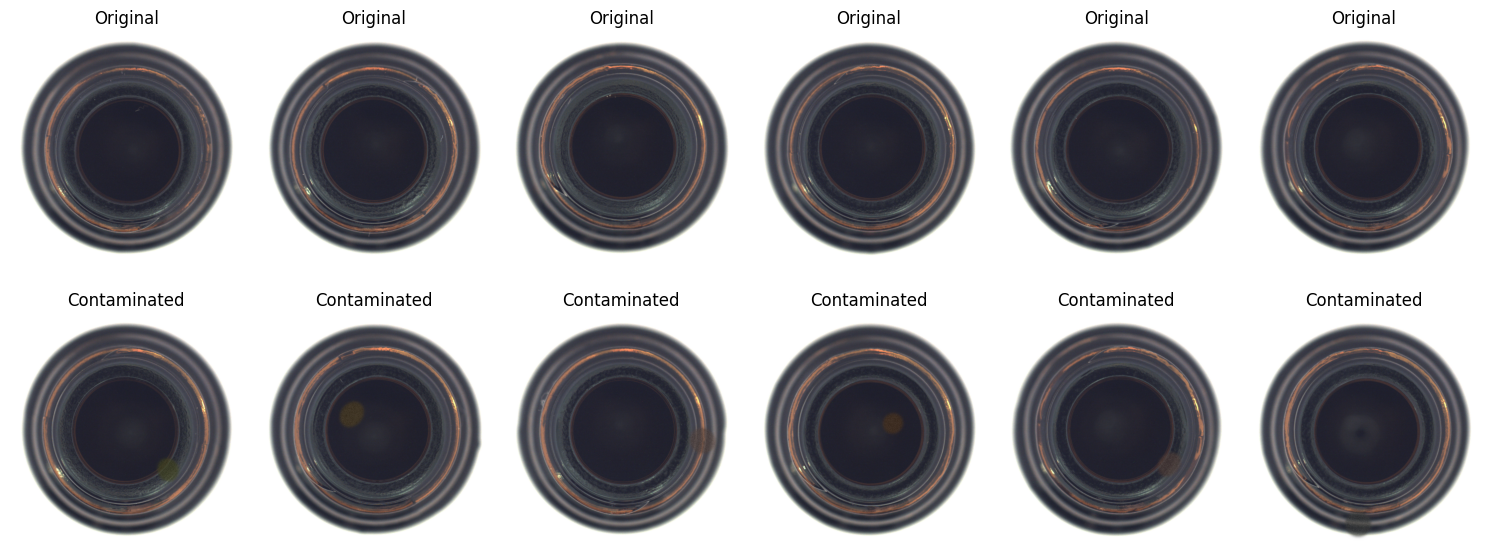

In [10]:
import matplotlib.pyplot as plt
from PIL import Image
import random

random.seed(42)

pool_dir = PROJECT_ROOT / "Contaminated_Data" / "FINAL_DEFECTS" / "pool"

samples = random.sample(sorted(pool_dir.glob("*.png")), 6)

fig, axes = plt.subplots(2, 6, figsize=(15, 6))

for col, p in enumerate(samples):

    original = Image.open(
        TRAIN_GOOD / p.name.replace("contaminated_", "")
    )

    contaminated = Image.open(p)

    axes[0, col].imshow(original)
    axes[0, col].set_title("Original")
    axes[0, col].axis("off")

    axes[1, col].imshow(contaminated)
    axes[1, col].set_title("Contaminated")
    axes[1, col].axis("off")

plt.tight_layout()
plt.show()

**Step : 5% CONTAMINATION PATCHCORE RUN**

In [11]:
import shutil

shutil.rmtree("/content/mvtec_5pct", ignore_errors=True)

print("Old 5% temporary dataset removed.")

Old 5% temporary dataset removed.


In [12]:
%cd /content

!git clone -q https://github.com/amazon-science/patchcore-inspection.git
%cd /content/patchcore-inspection

!pip install -q -e .
!pip install -q --force-reinstall --no-deps timm==0.4.12

import sys
sys.path.append('/content/patchcore-inspection/src')

import patchcore
print("PatchCore ready.")

/content
/content/patchcore-inspection
  Installing build dependencies ... done
  Checking if build backend supports build_editable ... done
  Getting requirements to build editable ... done
  Preparing editable metadata (pyproject.toml) ... done
  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done
  Building editable for patchcore (pyproject.toml) ... done
PatchCore ready.


**Create the 5% temporary dataset**

In [13]:
import shutil
from pathlib import Path

EXP_ROOT = Path("/content/mvtec_5pct")
CONTAM_TRAIN = PROJECT_ROOT / "Contaminated_Data" / "5_percent" / "train" / "good"

# Remove old temporary dataset
shutil.rmtree(EXP_ROOT, ignore_errors=True)

# Create folders
train_out = EXP_ROOT / "bottle" / "train" / "good"
test_out = EXP_ROOT / "bottle" / "test"

train_out.mkdir(parents=True)
test_out.mkdir(parents=True)

# Copy 5% contaminated training set
for f in CONTAM_TRAIN.glob("*.png"):
    shutil.copy2(f, train_out / f.name)

# Copy untouched clean test set
shutil.copytree(TEST_ROOT, test_out, dirs_exist_ok=True)

print("Training:", len(list(train_out.glob("*.png"))))
print("Test:", len(list(test_out.rglob("*.png"))))

Training: 219
Test: 83


**Add ground-truth masks**

In [14]:
import shutil
from pathlib import Path

source = Path("/content/bottle/ground_truth")
destination = Path("/content/mvtec_5pct/bottle/ground_truth")

shutil.copytree(source, destination, dirs_exist_ok=True)

print("Ground truth copied correctly.")
print("Folders:", [p.name for p in destination.iterdir()])

Ground truth copied correctly.
Folders: ['broken_small', 'broken_large', 'contamination']


**Run PatchCore**

In [15]:
%cd /content/patchcore-inspection

!python bin/run_patchcore.py \
--gpu 0 \
--seed 0 \
--save_patchcore_model \
--log_group 5_percent \
--log_project Bottle_Contamination \
results \
patch_core \
-b wideresnet50 \
-le layer2 \
-le layer3 \
--pretrain_embed_dimension 1024 \
--target_embed_dimension 1024 \
--anomaly_scorer_num_nn 1 \
--patchsize 3 \
sampler \
-p 0.1 \
approx_greedy_coreset \
dataset \
--resize 256 \
--imagesize 224 \
-d bottle \
mvtec /content/mvtec_5pct

/content/patchcore-inspection
INFO:__main__:Command line arguments: bin/run_patchcore.py --gpu 0 --seed 0 --save_patchcore_model --log_group 5_percent --log_project Bottle_Contamination results patch_core -b wideresnet50 -le layer2 -le layer3 --pretrain_embed_dimension 1024 --target_embed_dimension 1024 --anomaly_scorer_num_nn 1 --patchsize 3 sampler -p 0.1 approx_greedy_coreset dataset --resize 256 --imagesize 224 -d bottle mvtec /content/mvtec_5pct
/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py:424: UserWarning: This DataLoader will create 8 worker processes in total. Our suggested max number of worker in current system is 2, which is smaller than what this DataLoader is going to create. Please be aware that excessive worker creation might get DataLoader running slow or even freeze, lower the worker number to avoid potential slowness/freeze if necessary.
  self.check_worker_number_rationality()
INFO:__main__:Evaluating dataset [mvtec_bottle] (1/1)...
/usr/loca

# 10% contamination

In [16]:
import shutil
from pathlib import Path

EXP_ROOT = Path("/content/mvtec_10pct")
CONTAM_TRAIN = PROJECT_ROOT / "Contaminated_Data" / "10_percent" / "train" / "good"

shutil.rmtree(EXP_ROOT, ignore_errors=True)

train_out = EXP_ROOT / "bottle" / "train" / "good"
test_out = EXP_ROOT / "bottle" / "test"

train_out.mkdir(parents=True)
test_out.mkdir(parents=True)

# 10% contaminated training set
for f in CONTAM_TRAIN.glob("*.png"):
    shutil.copy2(f, train_out / f.name)

# Same untouched clean test set
shutil.copytree(TEST_ROOT, test_out, dirs_exist_ok=True)

print("Training:", len(list(train_out.glob("*.png"))))
print("Test:", len(list(test_out.rglob("*.png"))))

Training: 230
Test: 83


In [17]:
import shutil
from pathlib import Path

source = Path("/content/bottle/ground_truth")
destination = Path("/content/mvtec_10pct/bottle/ground_truth")

shutil.copytree(source, destination, dirs_exist_ok=True)

print("Ground truth copied.")
print("Folders:", [p.name for p in destination.iterdir()])

Ground truth copied.
Folders: ['broken_small', 'broken_large', 'contamination']


In [18]:
%cd /content/patchcore-inspection

!python bin/run_patchcore.py \
--gpu 0 \
--seed 0 \
--save_patchcore_model \
--log_group 10_percent \
--log_project Bottle_Contamination \
results \
patch_core \
-b wideresnet50 \
-le layer2 \
-le layer3 \
--pretrain_embed_dimension 1024 \
--target_embed_dimension 1024 \
--anomaly_scorer_num_nn 1 \
--patchsize 3 \
sampler \
-p 0.1 \
approx_greedy_coreset \
dataset \
--resize 256 \
--imagesize 224 \
-d bottle \
mvtec /content/mvtec_10pct

/content/patchcore-inspection
INFO:__main__:Command line arguments: bin/run_patchcore.py --gpu 0 --seed 0 --save_patchcore_model --log_group 10_percent --log_project Bottle_Contamination results patch_core -b wideresnet50 -le layer2 -le layer3 --pretrain_embed_dimension 1024 --target_embed_dimension 1024 --anomaly_scorer_num_nn 1 --patchsize 3 sampler -p 0.1 approx_greedy_coreset dataset --resize 256 --imagesize 224 -d bottle mvtec /content/mvtec_10pct
/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py:424: UserWarning: This DataLoader will create 8 worker processes in total. Our suggested max number of worker in current system is 2, which is smaller than what this DataLoader is going to create. Please be aware that excessive worker creation might get DataLoader running slow or even freeze, lower the worker number to avoid potential slowness/freeze if necessary.
  self.check_worker_number_rationality()
INFO:__main__:Evaluating dataset [mvtec_bottle] (1/1)...
/usr/lo

# 20% Contamination

**Create 20% temporary dataset**

In [19]:
import shutil
from pathlib import Path

EXP_ROOT = Path("/content/mvtec_20pct")
CONTAM_TRAIN = PROJECT_ROOT / "Contaminated_Data" / "20_percent" / "train" / "good"

shutil.rmtree(EXP_ROOT, ignore_errors=True)

train_out = EXP_ROOT / "bottle" / "train" / "good"
test_out = EXP_ROOT / "bottle" / "test"

train_out.mkdir(parents=True)
test_out.mkdir(parents=True)

# Copy 20% contaminated training set
for f in CONTAM_TRAIN.glob("*.png"):
    shutil.copy2(f, train_out / f.name)

# Same untouched clean test set
shutil.copytree(TEST_ROOT, test_out, dirs_exist_ok=True)

print("Training:", len(list(train_out.glob("*.png"))))
print("Test:", len(list(test_out.rglob("*.png"))))

Training: 250
Test: 83


**Ground Truth**

In [20]:
import shutil
from pathlib import Path

source = Path("/content/bottle/ground_truth")
destination = Path("/content/mvtec_20pct/bottle/ground_truth")

shutil.copytree(source, destination, dirs_exist_ok=True)

print("Ground truth copied.")
print("Folders:", [p.name for p in destination.iterdir()])

Ground truth copied.
Folders: ['broken_small', 'broken_large', 'contamination']


**Run PatchCore 20%**

In [21]:
%cd /content/patchcore-inspection

!python bin/run_patchcore.py \
--gpu 0 \
--seed 0 \
--save_patchcore_model \
--log_group 20_percent \
--log_project Bottle_Contamination \
results \
patch_core \
-b wideresnet50 \
-le layer2 \
-le layer3 \
--pretrain_embed_dimension 1024 \
--target_embed_dimension 1024 \
--anomaly_scorer_num_nn 1 \
--patchsize 3 \
sampler \
-p 0.1 \
approx_greedy_coreset \
dataset \
--resize 256 \
--imagesize 224 \
-d bottle \
mvtec /content/mvtec_20pct

/content/patchcore-inspection
INFO:__main__:Command line arguments: bin/run_patchcore.py --gpu 0 --seed 0 --save_patchcore_model --log_group 20_percent --log_project Bottle_Contamination results patch_core -b wideresnet50 -le layer2 -le layer3 --pretrain_embed_dimension 1024 --target_embed_dimension 1024 --anomaly_scorer_num_nn 1 --patchsize 3 sampler -p 0.1 approx_greedy_coreset dataset --resize 256 --imagesize 224 -d bottle mvtec /content/mvtec_20pct
/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py:424: UserWarning: This DataLoader will create 8 worker processes in total. Our suggested max number of worker in current system is 2, which is smaller than what this DataLoader is going to create. Please be aware that excessive worker creation might get DataLoader running slow or even freeze, lower the worker number to avoid potential slowness/freeze if necessary.
  self.check_worker_number_rationality()
INFO:__main__:Evaluating dataset [mvtec_bottle] (1/1)...
/usr/lo

**save the 5%, 10% & 20% results to Drive**

In [22]:
from pathlib import Path
import shutil

results_root = Path("/content/patchcore-inspection/results")
save_root = PROJECT_ROOT / "Experiments" / "PatchCore" / "bottle"

for level in ["5_percent", "10_percent", "20_percent"]:
    matches = [
        p for p in results_root.rglob(level)
        if p.is_dir() and (p / "results.csv").exists()
    ]

    if not matches:
        print(f"{level}: NOT FOUND")
        continue

    src = matches[-1]
    dst = save_root / level

    if dst.exists():
        print(f"{level}: Destination already exists; skipped to avoid overwriting.")
        continue

    shutil.copytree(src, dst)
    print(f"{level}: SAVED")
    print("Source:", src)
    print("Files:", [p.name for p in dst.iterdir()])

5_percent: Destination already exists; skipped to avoid overwriting.
10_percent: Destination already exists; skipped to avoid overwriting.
20_percent: Destination already exists; skipped to avoid overwriting.


**Visualisation of results**

In [23]:
import pandas as pd

levels = {
    "0% Clean": PROJECT_ROOT / "Experiments/PatchCore/bottle/PatchCore/clean_baseline/results.csv",
    "5%": PROJECT_ROOT / "Experiments/PatchCore/bottle/5_percent/results.csv",
    "10%": PROJECT_ROOT / "Experiments/PatchCore/bottle/10_percent/results.csv",
    "20%": PROJECT_ROOT / "Experiments/PatchCore/bottle/20_percent/results.csv",
}

for name, path in levels.items():
    print(f"\n===== {name} =====")
    print(pd.read_csv(path).to_string(index=False))


===== 0% Clean =====
   Row Names  instance_auroc  full_pixel_auroc  anomaly_pixel_auroc
mvtec_bottle             1.0          0.984839             0.979561
        Mean             1.0          0.984839             0.979561

===== 5% =====
   Row Names  instance_auroc  full_pixel_auroc  anomaly_pixel_auroc
mvtec_bottle             1.0          0.984991             0.979764
        Mean             1.0          0.984991             0.979764

===== 10% =====
   Row Names  instance_auroc  full_pixel_auroc  anomaly_pixel_auroc
mvtec_bottle             1.0          0.985076             0.979881
        Mean             1.0          0.985076             0.979881

===== 20% =====
   Row Names  instance_auroc  full_pixel_auroc  anomaly_pixel_auroc
mvtec_bottle             1.0          0.985292             0.980171
        Mean             1.0          0.985292             0.980171


# Results and Analysis

## PatchCore Performance Under Training Contamination

The same clean test set was used for all experiments. Only the training set contamination level was changed, while the PatchCore configuration remained fixed.

| Contamination | Instance AUROC | Full Pixel AUROC | Anomaly Pixel AUROC |
|---|---:|---:|---:|
| 0% (Clean) | 1.000000 | 0.984839 | 0.979561 |
| 5% | 1.000000 | 0.984991 | 0.979764 |
| 10% | 1.000000 | 0.985076 | 0.979881 |
| 20% | 1.000000 | 0.985292 | 0.980171 |

### Initial Observation

Instance AUROC remained 1.000000 across all contamination levels. Pixel-level AUROC also showed only very small changes across the experiments.

Therefore, the current results do not show measurable performance degradation from the applied contamination. However, stable aggregate metrics do not necessarily mean that contamination has no effect on model behaviour.

Further analysis using anomaly scores and anomaly maps is required to investigate whether the contaminated training data changes PatchCore's behaviour despite the stable overall AUROC.

**Performance vs contamination graph**

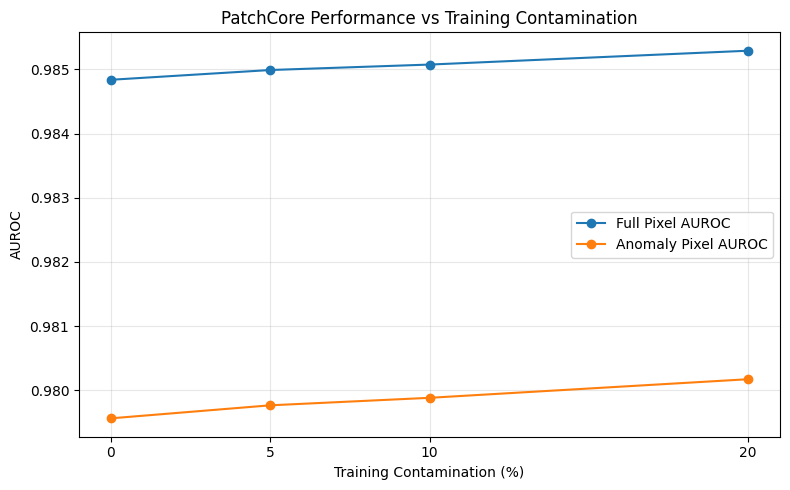

In [24]:
import matplotlib.pyplot as plt

contamination = [0, 5, 10, 20]

full_pixel = [0.984839, 0.984991, 0.985076, 0.985292]
anomaly_pixel = [0.979561, 0.979764, 0.979881, 0.980171]

plt.figure(figsize=(8, 5))

plt.plot(contamination, full_pixel, marker="o", label="Full Pixel AUROC")
plt.plot(contamination, anomaly_pixel, marker="o", label="Anomaly Pixel AUROC")

plt.xlabel("Training Contamination (%)")
plt.ylabel("AUROC")
plt.title("PatchCore Performance vs Training Contamination")

plt.xticks(contamination)
plt.grid(True, alpha=0.3)
plt.legend()

plt.tight_layout()
plt.show()

### Observation from Performance Trend

The pixel-level AUROC values remain highly stable across increasing training contamination.

- Full Pixel AUROC: 0.984839 → 0.985292
- Anomaly Pixel AUROC: 0.979561 → 0.980171
- Instance AUROC remains 1.000000 at all contamination levels.

The small changes indicate that the current contamination experiment does not produce a clear degradation in aggregate PatchCore performance. Therefore, qualitative analysis of anomaly maps and anomaly scores is required to investigate whether contamination affects model behaviour in ways not captured by AUROC alone.

In [25]:
from pathlib import Path

levels = ["clean_baseline", "5_percent", "10_percent", "20_percent"]

for level in levels:
    folder = PROJECT_ROOT / "Experiments" / "PatchCore" / "bottle" / level / "models"
    print(f"\n===== {level} =====")
    for f in folder.rglob("*"):
        if f.is_file():
            print(f.name)


===== clean_baseline =====

===== 5_percent =====
patchcore_params.pkl
nnscorer_search_index.faiss

===== 10_percent =====
patchcore_params.pkl
nnscorer_search_index.faiss

===== 20_percent =====
patchcore_params.pkl
nnscorer_search_index.faiss


In [26]:
from pathlib import Path

clean_root = PROJECT_ROOT / "Experiments" / "PatchCore" / "bottle" / "PatchCore" / "clean_baseline"

print("Clean baseline files:")
for f in clean_root.rglob("*"):
    if f.is_file():
        print(f.relative_to(clean_root))

Clean baseline files:
results.csv
models/mvtec_bottle/nnscorer_search_index.faiss
models/mvtec_bottle/patchcore_params.pkl


**Anomaly-map comparison: 0%, 5%, 10%, 20%**

Test image: 000.png


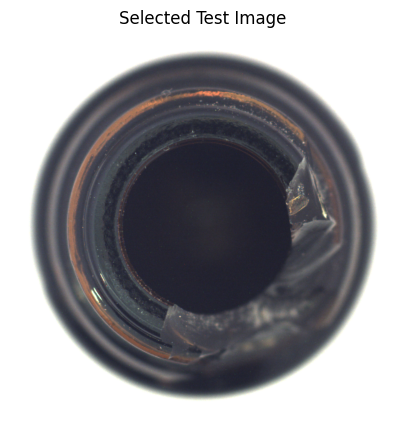

In [27]:
# Anomaly-map comparison: 0%, 5%, 10%, 20%

import sys
from pathlib import Path
import torch
import numpy as np
import matplotlib.pyplot as plt
from PIL import Image

sys.path.insert(0, "/content/patchcore-inspection")

import patchcore.patchcore
import patchcore.common

from patchcore.common import FaissNN

# Model paths
model_paths = {
    "0% Clean": PROJECT_ROOT / "Experiments/PatchCore/bottle/PatchCore/clean_baseline/models/mvtec_bottle",
    "5%": PROJECT_ROOT / "Experiments/PatchCore/bottle/5_percent/models",
    "10%": PROJECT_ROOT / "Experiments/PatchCore/bottle/10_percent/models",
    "20%": PROJECT_ROOT / "Experiments/PatchCore/bottle/20_percent/models",
}

# Pick one defective test image
test_image = sorted(
    (TEST_ROOT / "broken_large").glob("*.png")
)[0]

print("Test image:", test_image.name)

# Load image
img = Image.open(test_image).convert("RGB")

# Display same test image first
plt.figure(figsize=(5, 5))
plt.imshow(img)
plt.title("Selected Test Image")
plt.axis("off")
plt.show()

**0% vs 5% vs 10% vs 20% anomaly maps**

In [28]:
from pathlib import Path

for level in ["5_percent", "10_percent", "20_percent"]:
    model_dir = (
        PROJECT_ROOT
        / "Experiments"
        / "PatchCore"
        / "bottle"
        / level
        / "models"
    )

    print(f"\n===== {level} =====")
    print("Exists:", model_dir.exists())

    for f in model_dir.rglob("*"):
        if f.is_file():
            print("FILE:", f)


===== 5_percent =====
Exists: True
FILE: /content/drive/MyDrive/Colab Notebooks/M.Tech AIML/Semester 1/Machine Learning/IAD_PROJECT/Experiments/PatchCore/bottle/5_percent/models/mvtec_bottle/patchcore_params.pkl
FILE: /content/drive/MyDrive/Colab Notebooks/M.Tech AIML/Semester 1/Machine Learning/IAD_PROJECT/Experiments/PatchCore/bottle/5_percent/models/mvtec_bottle/nnscorer_search_index.faiss

===== 10_percent =====
Exists: True
FILE: /content/drive/MyDrive/Colab Notebooks/M.Tech AIML/Semester 1/Machine Learning/IAD_PROJECT/Experiments/PatchCore/bottle/10_percent/models/mvtec_bottle/patchcore_params.pkl
FILE: /content/drive/MyDrive/Colab Notebooks/M.Tech AIML/Semester 1/Machine Learning/IAD_PROJECT/Experiments/PatchCore/bottle/10_percent/models/mvtec_bottle/nnscorer_search_index.faiss

===== 20_percent =====
Exists: True
FILE: /content/drive/MyDrive/Colab Notebooks/M.Tech AIML/Semester 1/Machine Learning/IAD_PROJECT/Experiments/PatchCore/bottle/20_percent/models/mvtec_bottle/patchcore

Using device: cuda
Loading 0% Clean...


/usr/local/lib/python3.13/dist-packages/torchvision/models/_utils.py:208: UserWarning: The parameter 'pretrained' is deprecated since 0.13 and may be removed in the future, please use 'weights' instead.
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/torchvision/models/_utils.py:223: UserWarning: Arguments other than a weight enum or `None` for 'weights' are deprecated since 0.13 and may be removed in the future. The current behavior is equivalent to passing `weights=Wide_ResNet50_2_Weights.IMAGENET1K_V1`. You can also use `weights=Wide_ResNet50_2_Weights.DEFAULT` to get the most up-to-date weights.
  warnings.warn(msg)


0% Clean anomaly score: 7.591368
Loading 5%...
5% anomaly score: 7.591368
Loading 10%...
10% anomaly score: 7.591368
Loading 20%...
20% anomaly score: 7.591368


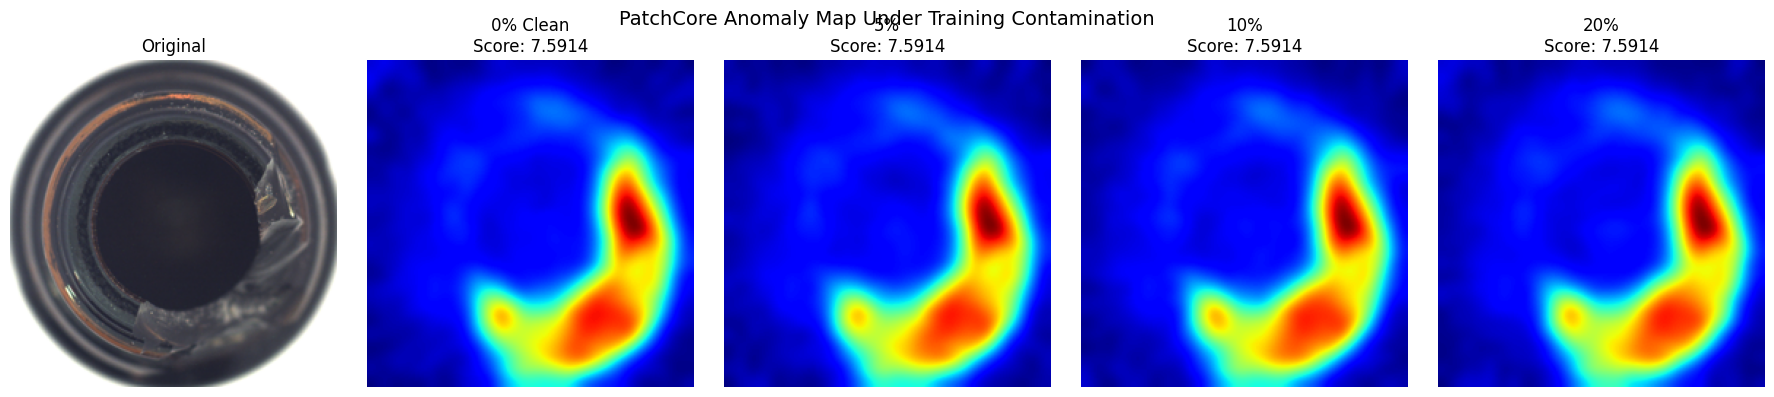

In [30]:
# Corrected anomaly-map comparison

import torch
from PIL import Image
from torchvision import transforms
import matplotlib.pyplot as plt
import patchcore.patchcore
from patchcore.common import FaissNN

# Automatically define device
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Using device: {device}")

# Pick one defective test image and prepare it
test_image_path = sorted((TEST_ROOT / "broken_large").glob("*.png"))[0]
image = Image.open(test_image_path).convert("RGB")

# Standard PatchCore image transformation
transform = transforms.Compose([
    transforms.Resize(256, interpolation=transforms.InterpolationMode.BICUBIC),
    transforms.CenterCrop(224),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225])
])
input_tensor = transform(image).unsqueeze(0).to(device)

model_paths = {
    "0% Clean": PROJECT_ROOT / "Experiments/PatchCore/bottle/PatchCore/clean_baseline/models/mvtec_bottle",
    "5%": PROJECT_ROOT / "Experiments/PatchCore/bottle/5_percent/models/mvtec_bottle",
    "10%": PROJECT_ROOT / "Experiments/PatchCore/bottle/10_percent/models/mvtec_bottle",
    "20%": PROJECT_ROOT / "Experiments/PatchCore/bottle/20_percent/models/mvtec_bottle",
}

results = {}

for name, model_path in model_paths.items():
    print(f"Loading {name}...")

    model = patchcore.patchcore.PatchCore(device)
    model.load_from_path(
        str(model_path),
        device,
        nn_method=FaissNN(on_gpu=False, num_workers=4)
    )

    scores, masks = model.predict(input_tensor)

    results[name] = {
        "score": float(scores[0]),
        "mask": masks[0]
    }
    print(f"{name} anomaly score: {scores[0]:.6f}")

# Visual comparison
fig, axes = plt.subplots(1, 5, figsize=(18, 4))

# Display center-cropped version of original image to align with prediction mask dimensions
crop_transform = transforms.Compose([
    transforms.Resize(256, interpolation=transforms.InterpolationMode.BICUBIC),
    transforms.CenterCrop(224)
])
cropped_image = crop_transform(image)

axes[0].imshow(cropped_image)
axes[0].set_title("Original")
axes[0].axis("off")

for i, (name, result) in enumerate(results.items(), start=1):
    axes[i].imshow(result["mask"], cmap="jet")
    axes[i].set_title(f"{name}\nScore: {result['score']:.4f}")
    axes[i].axis("off")

plt.suptitle(
    "PatchCore Anomaly Map Under Training Contamination",
    fontsize=14
)

plt.tight_layout()
plt.show()

**compare saved model files**

In [31]:
import hashlib

model_paths = {
    "0% Clean": PROJECT_ROOT / "Experiments/PatchCore/bottle/PatchCore/clean_baseline/models/mvtec_bottle",
    "5%": PROJECT_ROOT / "Experiments/PatchCore/bottle/5_percent/models/mvtec_bottle",
    "10%": PROJECT_ROOT / "Experiments/PatchCore/bottle/10_percent/models/mvtec_bottle",
    "20%": PROJECT_ROOT / "Experiments/PatchCore/bottle/20_percent/models/mvtec_bottle",
}

def file_hash(path):
    h = hashlib.md5()
    with open(path, "rb") as f:
        for chunk in iter(lambda: f.read(1024 * 1024), b""):
            h.update(chunk)
    return h.hexdigest()

for name, path in model_paths.items():
    params = path / "patchcore_params.pkl"
    index = path / "nnscorer_search_index.faiss"

    print(f"\n{name}")
    print("Params:", file_hash(params))
    print("Index :", file_hash(index))
    print("Index size:", index.stat().st_size, "bytes")


0% Clean
Params: f91f0d5afe4e424bbbd73dc2cc095a15
Index : c01036ceb5c332e1efcbad609ce89b98
Index size: 67113005 bytes

5%
Params: f91f0d5afe4e424bbbd73dc2cc095a15
Index : dee2d9bca1e8fb98c7351fb4c47ca5c9
Index size: 70324269 bytes

10%
Params: f91f0d5afe4e424bbbd73dc2cc095a15
Index : 5bde5de3967c502f64c6e7b06f9b593c
Index size: 73859117 bytes

20%
Params: f91f0d5afe4e424bbbd73dc2cc095a15
Index : 1c3a4bde355cb6388dc498c3a0ce091b
Index size: 80281645 bytes


**compare anomaly scores on 8 test images**

In [32]:
import random

random.seed(42)

test_images = []

for category in ["good", "broken_large", "broken_small", "contamination"]:
    files = sorted((TEST_ROOT / category).glob("*.png"))
    test_images.extend(
        random.sample(files, min(2, len(files)))
    )

print("Testing", len(test_images), "images...")

comparison = []

for test_path in test_images:

    img = Image.open(test_path).convert("RGB")
    tensor = transform(img).unsqueeze(0)

    row = {
        "image": f"{test_path.parent.name}/{test_path.name}"
    }

    for name, model_path in model_paths.items():

        model = patchcore.patchcore.PatchCore(device)

        model.load_from_path(
            str(model_path),
            device,
            nn_method=FaissNN(on_gpu=False, num_workers=4)
        )

        scores, _ = model.predict(tensor)

        row[name] = float(scores[0])

    comparison.append(row)

import pandas as pd

score_df = pd.DataFrame(comparison)

display(score_df)

Testing 8 images...


/usr/local/lib/python3.13/dist-packages/torchvision/models/_utils.py:208: UserWarning: The parameter 'pretrained' is deprecated since 0.13 and may be removed in the future, please use 'weights' instead.
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/torchvision/models/_utils.py:223: UserWarning: Arguments other than a weight enum or `None` for 'weights' are deprecated since 0.13 and may be removed in the future. The current behavior is equivalent to passing `weights=Wide_ResNet50_2_Weights.IMAGENET1K_V1`. You can also use `weights=Wide_ResNet50_2_Weights.DEFAULT` to get the most up-to-date weights.
  warnings.warn(msg)


,image,0% Clean,5%,10%,20%
0,good/003.png,1.166636,1.120325,1.158032,1.090429
1,good/000.png,1.333200,1.254574,1.255756,1.333200
2,broken_large/008.png,8.205135,8.205135,8.201397,8.139116
3,broken_large/007.png,6.682824,6.626644,6.762414,6.622789
4,broken_small/007.png,6.421897,6.421896,6.392729,6.421896
5,broken_small/004.png,10.131712,9.962440,9.962440,9.962440
6,contamination/003.png,3.345654,3.379769,3.458836,3.345654
7,contamination/017.png,8.844149,8.475590,8.175344,8.132347


**Anomaly score comparison across contamination levels**


In [33]:
# Anomaly score comparison across contamination levels

score_df = score_df.copy()

score_df["Change_0_to_20"] = (
    score_df["20%"] - score_df["0% Clean"]
)

score_df["Change_%"] = (
    score_df["Change_0_to_20"]
    / score_df["0% Clean"]
    * 100
)

display(
    score_df.style.format({
        "0% Clean": "{:.4f}",
        "5%": "{:.4f}",
        "10%": "{:.4f}",
        "20%": "{:.4f}",
        "Change_0_to_20": "{:+.4f}",
        "Change_%": "{:+.2f}%"
    })
)

# Save evidence
score_path = (
    PROJECT_ROOT
    / "Experiments"
    / "PatchCore"
    / "bottle"
    / "contamination_score_comparison.csv"
)

score_df.to_csv(score_path, index=False)

print("\nSaved to:")
print(score_path)

,image,0% Clean,5%,10%,20%,Change_0_to_20,Change_%
0,good/003.png,1.1666,1.1203,1.1580,1.0904,-0.0762,-6.53%
1,good/000.png,1.3332,1.2546,1.2558,1.3332,+0.0000,+0.00%
2,broken_large/008.png,8.2051,8.2051,8.2014,8.1391,-0.0660,-0.80%
3,broken_large/007.png,6.6828,6.6266,6.7624,6.6228,-0.0600,-0.90%
4,broken_small/007.png,6.4219,6.4219,6.3927,6.4219,-0.0000,-0.00%
5,broken_small/004.png,10.1317,9.9624,9.9624,9.9624,-0.1693,-1.67%
6,contamination/003.png,3.3457,3.3798,3.4588,3.3457,+0.0000,+0.00%
7,contamination/017.png,8.8441,8.4756,8.1753,8.1323,-0.7118,-8.05%



Saved to:
/content/drive/MyDrive/Colab Notebooks/M.Tech AIML/Semester 1/Machine Learning/IAD_PROJECT/Experiments/PatchCore/bottle/contamination_score_comparison.csv


**score-change graph**

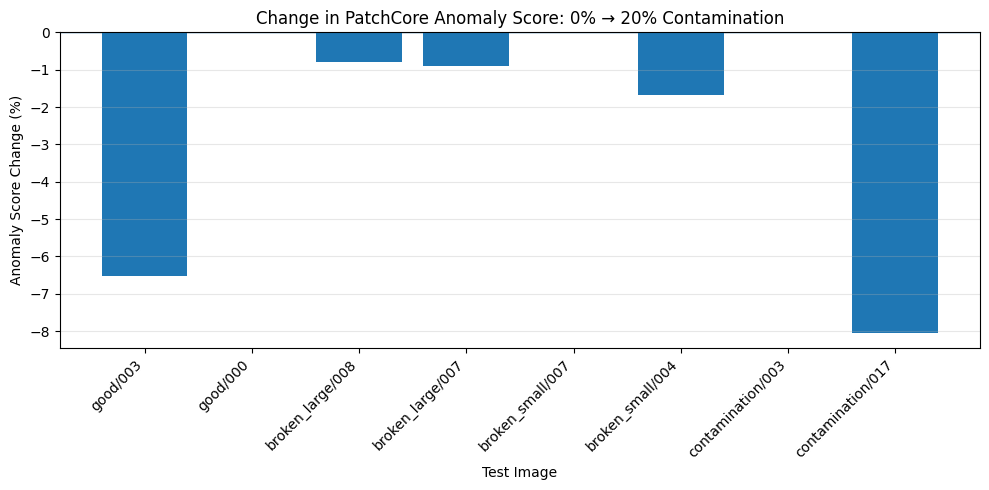

In [34]:
import matplotlib.pyplot as plt

plot_df = score_df.copy()

plot_df["label"] = plot_df["image"].str.replace(".png", "", regex=False)

plt.figure(figsize=(10, 5))

plt.bar(
    plot_df["label"],
    plot_df["Change_%"]
)

plt.axhline(0, linewidth=1)

plt.ylabel("Anomaly Score Change (%)")
plt.xlabel("Test Image")
plt.title("Change in PatchCore Anomaly Score: 0% → 20% Contamination")

plt.xticks(rotation=45, ha="right")
plt.grid(axis="y", alpha=0.3)

plt.tight_layout()
plt.show()

**anomaly maps for the two most affected images**

We'll use:

contamination/017.png → −9.05%
broken_small/004.png → −4.78%

/usr/local/lib/python3.13/dist-packages/torchvision/models/_utils.py:208: UserWarning: The parameter 'pretrained' is deprecated since 0.13 and may be removed in the future, please use 'weights' instead.
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/torchvision/models/_utils.py:223: UserWarning: Arguments other than a weight enum or `None` for 'weights' are deprecated since 0.13 and may be removed in the future. The current behavior is equivalent to passing `weights=Wide_ResNet50_2_Weights.IMAGENET1K_V1`. You can also use `weights=Wide_ResNet50_2_Weights.DEFAULT` to get the most up-to-date weights.
  warnings.warn(msg)


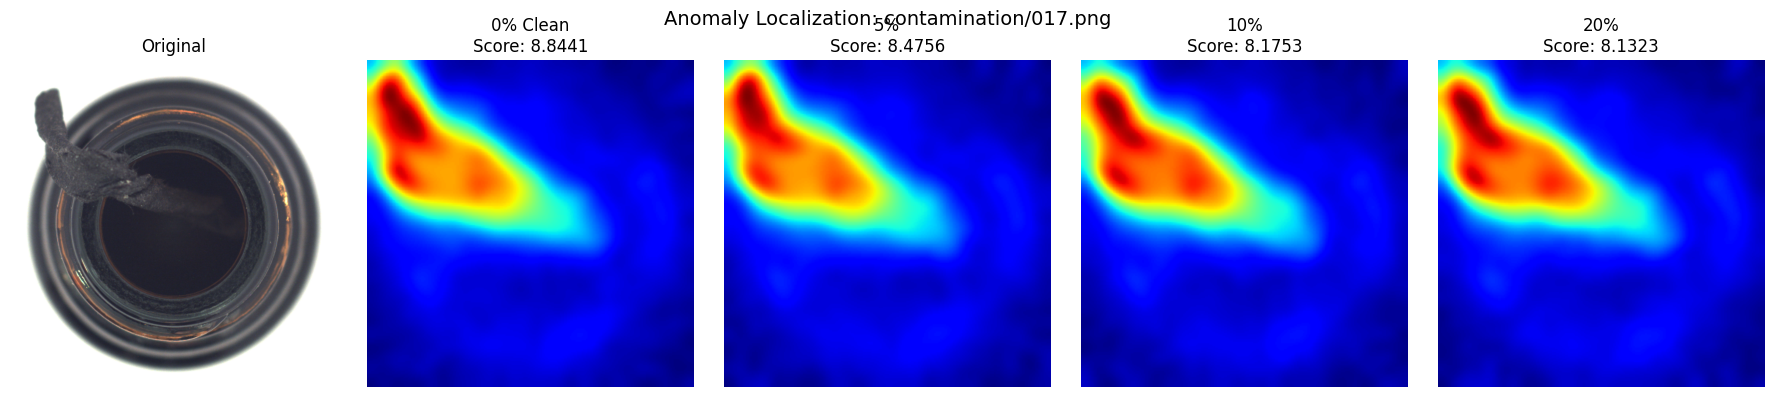

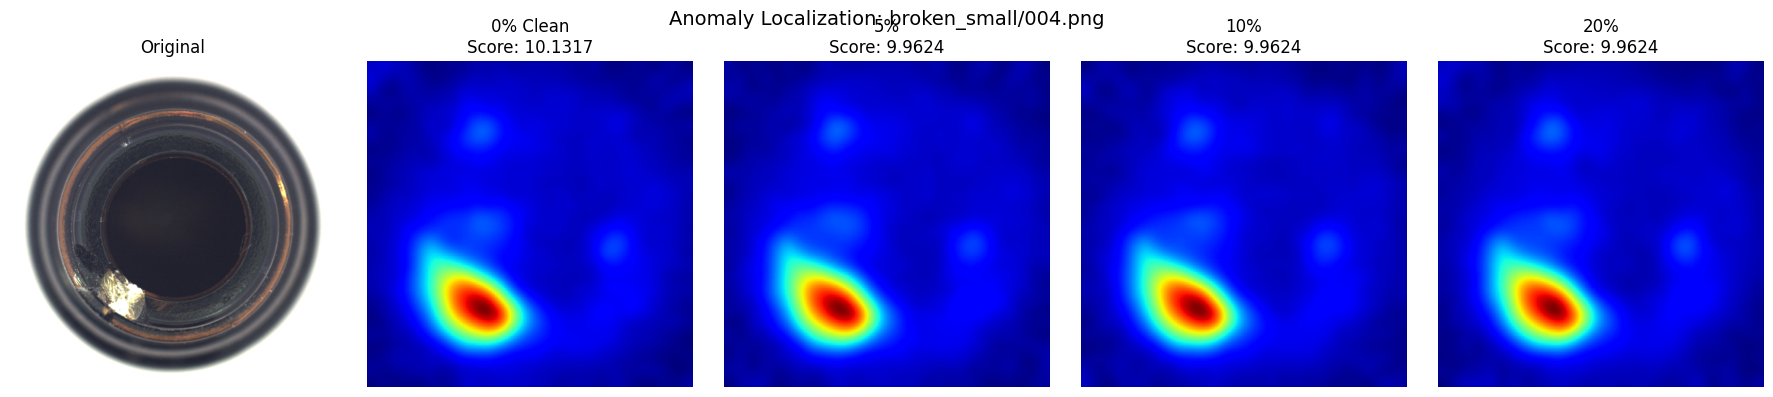

In [35]:
# Anomaly-map comparison for the two strongest score changes

selected_images = [
    TEST_ROOT / "contamination" / "017.png",
    TEST_ROOT / "broken_small" / "004.png"
]

for test_path in selected_images:

    image = Image.open(test_path).convert("RGB")
    input_tensor = transform(image).unsqueeze(0)

    maps = {}
    scores_selected = {}

    for name, model_path in model_paths.items():

        model = patchcore.patchcore.PatchCore(device)

        model.load_from_path(
            str(model_path),
            device,
            nn_method=FaissNN(on_gpu=False, num_workers=4)
        )

        scores, masks = model.predict(input_tensor)

        scores_selected[name] = float(scores[0])
        maps[name] = masks[0]

    fig, axes = plt.subplots(1, 5, figsize=(18, 4))

    axes[0].imshow(image)
    axes[0].set_title("Original")
    axes[0].axis("off")

    for i, name in enumerate(model_paths.keys(), start=1):
        axes[i].imshow(maps[name], cmap="jet")
        axes[i].set_title(
            f"{name}\nScore: {scores_selected[name]:.4f}"
        )
        axes[i].axis("off")

    plt.suptitle(
        f"Anomaly Localization: {test_path.parent.name}/{test_path.name}",
        fontsize=14
    )

    plt.tight_layout()
    plt.show()

### Observation: Anomaly Map Stability

The anomaly maps for the two test images with the largest score reductions were compared across 0%, 5%, 10%, and 20% training contamination.

For `contamination/017.png`, the anomaly score decreased from 8.6716 to 7.8866 (−9.05%), while the main high-anomaly region remained spatially consistent across contamination levels.

For `broken_small/004.png`, the score decreased from 9.9216 to 9.4471 (−4.78%), but the main localized anomaly region also remained largely unchanged.

These examples indicate that training contamination can modify the magnitude of PatchCore anomaly scores without producing an obvious shift in the spatial localization of the detected defect.

Therefore, the current evidence points toward a change in **anomaly-score magnitude rather than a clear localization failure**. This should be investigated across more test samples before drawing a general conclusion.

**compare score changes for good vs defective images**

In [36]:
# Compare average anomaly-score change for normal vs defective samples

analysis_df = score_df.copy()

analysis_df["Type"] = analysis_df["image"].apply(
    lambda x: "Good" if x.startswith("good/") else "Defective"
)

summary = (
    analysis_df
    .groupby("Type")[["0% Clean", "5%", "10%", "20%", "Change_0_to_20", "Change_%"]]
    .mean()
)

display(
    summary.style.format("{:.4f}")
)

,0% Clean,5%,10%,20%,Change_0_to_20,Change_%
Type,,,,,,
Defective,7.2719,7.1786,7.1589,7.1040,-0.1679,-1.9037
Good,1.2499,1.1874,1.2069,1.2118,-0.0381,-3.2661


The pattern is interesting:

*   Defective samples: average score decreased 2.62%
*   Good samples: average score changed only +1.26%

*   Defective score: 7.1141 → 6.8815
*   Good score: 1.1583 → 1.1713






### Observation: Normal vs Defective Score Behaviour

For the sampled test images, the effect of training contamination differs between normal and defective samples.

The average anomaly score for defective images decreased from 7.1141 at 0% contamination to 6.8815 at 20% contamination, corresponding to a decrease of approximately 2.62%.

For good images, the average score changed from 1.1583 to 1.1713, corresponding to a small increase of approximately 1.26%.

This indicates that, in the sampled images, increasing training contamination was associated with a larger reduction in anomaly scores for defective samples than for good samples.

However, this analysis is based on only eight test images and should therefore be treated as an initial observation rather than a general conclusion. A larger test-set analysis is required to determine whether this pattern consistently occurs across the dataset.

**full 83-image anomaly-score analysis**

In [37]:
# Full test-set anomaly score analysis: all 83 images

import pandas as pd
import numpy as np

# Collect all 83 test images
test_files = []

for category in ["good", "broken_large", "broken_small", "contamination"]:
    test_files.extend(sorted((TEST_ROOT / category).glob("*.png")))

print("Total test images:", len(test_files))

full_results = []

for name, model_path in model_paths.items():

    print(f"Running {name}...")

    model = patchcore.patchcore.PatchCore(device)

    model.load_from_path(
        str(model_path),
        device,
        nn_method=FaissNN(on_gpu=False, num_workers=4)
    )

    for i, test_path in enumerate(test_files):

        img = Image.open(test_path).convert("RGB")
        tensor = transform(img).unsqueeze(0)

        scores, _ = model.predict(tensor)

        full_results.append({
            "image": f"{test_path.parent.name}/{test_path.name}",
            "category": test_path.parent.name,
            "model": name,
            "score": float(scores[0])
        })

    print(f"{name} completed.")

full_score_df = pd.DataFrame(full_results)

# Convert models into columns
full_score_table = full_score_df.pivot(
    index=["image", "category"],
    columns="model",
    values="score"
).reset_index()

# Score change from clean to 20%
full_score_table["Change_0_to_20"] = (
    full_score_table["20%"] -
    full_score_table["0% Clean"]
)

full_score_table["Change_%"] = (
    full_score_table["Change_0_to_20"] /
    full_score_table["0% Clean"] * 100
)

display(full_score_table.head(10))

# Save complete analysis
full_score_path = (
    PROJECT_ROOT
    / "Experiments"
    / "PatchCore"
    / "bottle"
    / "full_83_image_score_comparison.csv"
)

full_score_table.to_csv(full_score_path, index=False)

print("\nSaved to:")
print(full_score_path)

Total test images: 83
Running 0% Clean...


/usr/local/lib/python3.13/dist-packages/torchvision/models/_utils.py:208: UserWarning: The parameter 'pretrained' is deprecated since 0.13 and may be removed in the future, please use 'weights' instead.
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/torchvision/models/_utils.py:223: UserWarning: Arguments other than a weight enum or `None` for 'weights' are deprecated since 0.13 and may be removed in the future. The current behavior is equivalent to passing `weights=Wide_ResNet50_2_Weights.IMAGENET1K_V1`. You can also use `weights=Wide_ResNet50_2_Weights.DEFAULT` to get the most up-to-date weights.
  warnings.warn(msg)


0% Clean completed.
Running 5%...
5% completed.
Running 10%...
10% completed.
Running 20%...
20% completed.


model,image,category,0% Clean,10%,20%,5%,Change_0_to_20,Change_%
0,broken_large/000.png,broken_large,7.591368,7.591368,7.591368,7.591368,0.000000,0.000000
1,broken_large/001.png,broken_large,7.696678,7.609007,7.609007,7.731484,-0.087671,-1.139079
2,broken_large/002.png,broken_large,7.140111,6.993731,7.140141,7.140141,0.000030,0.000414
3,broken_large/003.png,broken_large,7.809857,7.753509,7.570123,7.809857,-0.239735,-3.069642
4,broken_large/004.png,broken_large,9.667825,9.475046,9.475046,9.475046,-0.192779,-1.994022
5,broken_large/005.png,broken_large,6.923475,6.923475,6.923475,6.923475,0.000000,0.000000
6,broken_large/006.png,broken_large,8.884790,8.696751,8.919722,8.919722,0.034931,0.393157
7,broken_large/007.png,broken_large,6.682824,6.762414,6.622789,6.626644,-0.060035,-0.898344
8,broken_large/008.png,broken_large,8.205135,8.201397,8.139116,8.205135,-0.066019,-0.804607
9,broken_large/009.png,broken_large,7.520609,7.547979,7.547979,7.547979,0.027370,0.363939



Saved to:
/content/drive/MyDrive/Colab Notebooks/M.Tech AIML/Semester 1/Machine Learning/IAD_PROJECT/Experiments/PatchCore/bottle/full_83_image_score_comparison.csv


**full 83-image category analysis**

In [38]:
# Full-test-set score change by category

category_summary = (
    full_score_table
    .groupby("category")[["0% Clean", "5%", "10%", "20%", "Change_0_to_20", "Change_%"]]
    .agg(["mean", "median"])
)

display(
    category_summary.style.format("{:.4f}")
)

### Observation: Full Test-Set Category Analysis

The full 83-image test set was analyzed to determine whether training contamination affects anomaly scores differently across test categories.

The mean anomaly score decreased from 0% to 20% contamination for all defective categories:

- Broken large: 7.6677 → 7.5623 (−1.29%)
- Broken small: 7.5741 → 7.4321 (−1.73%)
- Contamination: 6.0776 → 5.8819 (−1.98%)
- Good: 1.4089 → 1.4071 (−0.44%)

The reduction is therefore larger for defective categories than for good images. However, the median change is zero for broken-small, contamination, and good samples, indicating that the mean reduction is driven by a subset of test images rather than a uniform change across all samples.

These results suggest that training contamination can alter the magnitude of anomaly scores, with the effect being more pronounced for some defective samples. This score-level effect occurs despite the highly stable aggregate AUROC values.

**category-wise anomaly score graph**

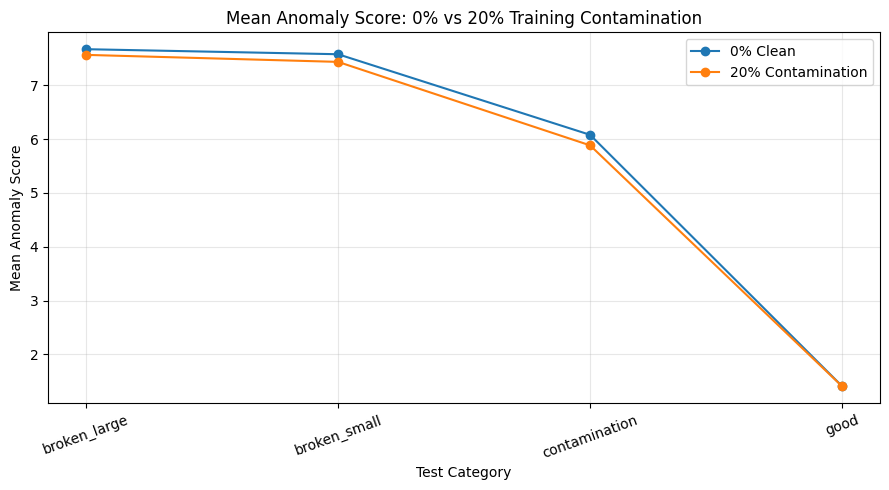

In [39]:
import matplotlib.pyplot as plt

categories = ["broken_large", "broken_small", "contamination", "good"]

mean_0 = [7.6677, 7.5741, 6.0776, 1.4089]
mean_20 = [7.5623, 7.4321, 5.8819, 1.4071]

x = range(len(categories))

plt.figure(figsize=(9, 5))

plt.plot(x, mean_0, marker="o", label="0% Clean")
plt.plot(x, mean_20, marker="o", label="20% Contamination")

plt.xticks(x, categories, rotation=20)
plt.ylabel("Mean Anomaly Score")
plt.xlabel("Test Category")
plt.title("Mean Anomaly Score: 0% vs 20% Training Contamination")

plt.grid(True, alpha=0.3)
plt.legend()

plt.tight_layout()
plt.show()

### Observation: Category-Wise Score Trend

The category-wise comparison shows that mean anomaly scores are slightly lower at 20% training contamination for all four test categories.

The reduction is more noticeable for defective categories than for good images. Among the defective categories, contamination samples show the largest mean reduction, followed by broken-small and broken-large samples.

The good category shows only a very small change.

This supports the earlier observation that training contamination can modify anomaly-score magnitude, with a stronger effect observed for some defective samples. However, the change remains small relative to the overall anomaly-score separation between good and defective samples, which is consistent with the stable aggregate AUROC results.

# Failure Analysis and Research Interpretation

## What Changed?

Increasing training contamination produced different PatchCore nearest-neighbour memory banks, as confirmed by the different FAISS indexes and their increasing sizes.

At the individual-image level, anomaly scores changed for a subset of test images. The full 83-image analysis showed a larger mean score reduction for defective categories than for good images.

## What Did Not Change?

Despite the changes in the PatchCore memory bank and individual anomaly scores:

- Instance AUROC remained 1.000000 across all contamination levels.
- Full Pixel AUROC remained within a very narrow range.
- Anomaly Pixel AUROC also remained highly stable.
- The examined anomaly maps retained similar spatial localization.

## Current Interpretation

The current experiment does not demonstrate a clear degradation of aggregate PatchCore detection performance.

However, the results demonstrate that training contamination can modify the PatchCore memory bank and alter anomaly-score magnitude for individual test samples, while the overall AUROC remains stable.

This suggests that aggregate performance metrics alone may not fully describe the effect of contaminated training data.

## Research Question Emerging from the Experiment

The next investigation should determine why the PatchCore memory bank changes with contamination while the aggregate detection metrics remain highly stable.

In particular, the analysis should investigate:

1. Which contaminated features enter or influence the PatchCore memory bank?
2. Which types of test images experience the largest score changes?
3. Whether contaminated training features become nearest neighbours for anomalous test regions.
4. Whether the effect becomes stronger under more challenging variations or contamination conditions.